# Reproducing the figures

Every figure in `main.pdf`, in paper order, with the script that draws it.
Numbering and inputs follow `docs/PROVENANCE.md`.

Run from the repository root:

```bash
pip install -r requirements.txt
jupyter lab notebooks/reproduce_figures.ipynb
```

**Fig. F.1 is the one exception** - it reads a training-corpus scan that is not
shipped. Every other cell runs on repository files alone.


In [1]:
import os, subprocess, sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "main.tex").exists():          # allow running from notebooks/
    ROOT = ROOT.parent
os.chdir(ROOT)
print("repo root:", ROOT)

def run(script, args=(), cwd=None):
    """Run a figure script and report what it wrote."""
    p = Path(script)
    target = p.resolve() if cwd else p
    if not target.exists():
        print(f"SKIP  {script} (not present)"); return
    r = subprocess.run([sys.executable, str(target), *args],
                       cwd=cwd or ROOT, capture_output=True, text=True)
    print(("OK   " if r.returncode == 0 else "FAIL ") + str(script))
    for line in (r.stdout + r.stderr).strip().splitlines()[-8:]:
        print("   ", line)

def show(pdf, dpi=100):
    """Render a produced figure inline.

    Rasterises the PDF itself rather than reaching for a PNG twin, so every
    figure appears -- and at a fixed, modest resolution, which keeps the
    executed notebook small enough for GitHub to render quickly.
    """
    from IPython.display import display, Image, FileLink
    p = Path(pdf)
    if not p.exists():
        print(f"missing {pdf}"); return
    try:
        import pymupdf
        pix = pymupdf.open(p)[0].get_pixmap(dpi=dpi)
        display(Image(data=pix.tobytes("png")))
    except Exception as e:                      # no pymupdf, or a damaged file
        png = p.with_suffix(".png")
        display(Image(str(png))) if png.exists() else display(FileLink(pdf))


repo root: /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026


## Fig. 1

`figures/Fig1_setup.pdf` <- `code/figure_1_task_and_association/compose_fig1.py`


OK   code/figure_1_task_and_association/compose_fig1.py
    wrote figures/Fig1_setup.pdf  396 x 337 pt
    flattened figures/Fig1_setup.pdf  893 kB -> 541 kB, 0 embedded xobjects remaining


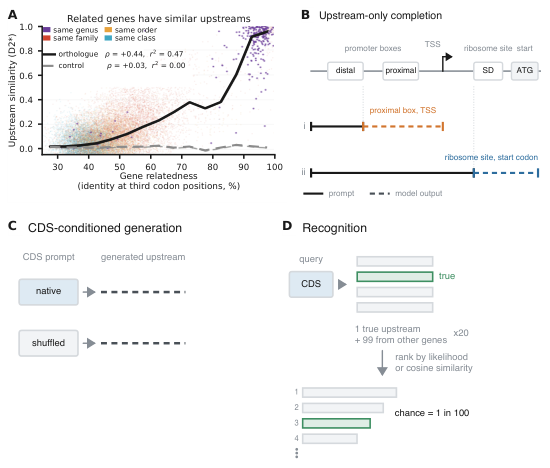

In [2]:
run("code/figure_1_task_and_association/compose_fig1.py")
show("figures/Fig1_setup.pdf")

## Fig. 2

`figures/fig_upstream_only_v2.pdf` <- `code/figure_2_promoter_element_placement/make_figure_v2.py`


OK   code/figure_2_promoter_element_placement/make_figure_v2.py
    wrote fig_main_2x2.pdf / .png


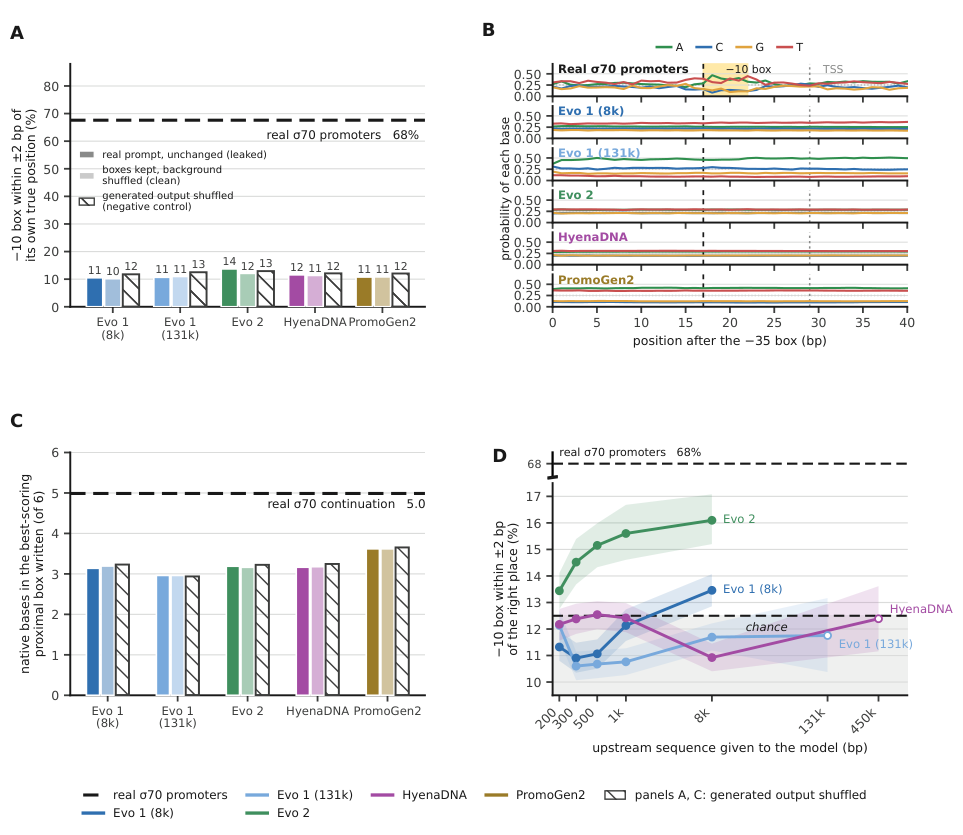

In [3]:
run("code/figure_2_promoter_element_placement/make_figure_v2.py")
show("figures/fig_upstream_only_v2.pdf")

## Fig. 3

`figures/cds_prompted_main.pdf` <- `code/figure_3_cds_conditioning/render_fig_testset.py`


OK   code/figure_3_cds_conditioning/render_fig_testset.py
    153 cached arrays
    wrote cds_prompted_main.{pdf,png} to results/ and figures/
    wrote cds_prompted_supp_cai.{pdf,png}
    /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/code/figure_3_cds_conditioning/render_fig_testset.py:146: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
      plt.tight_layout();


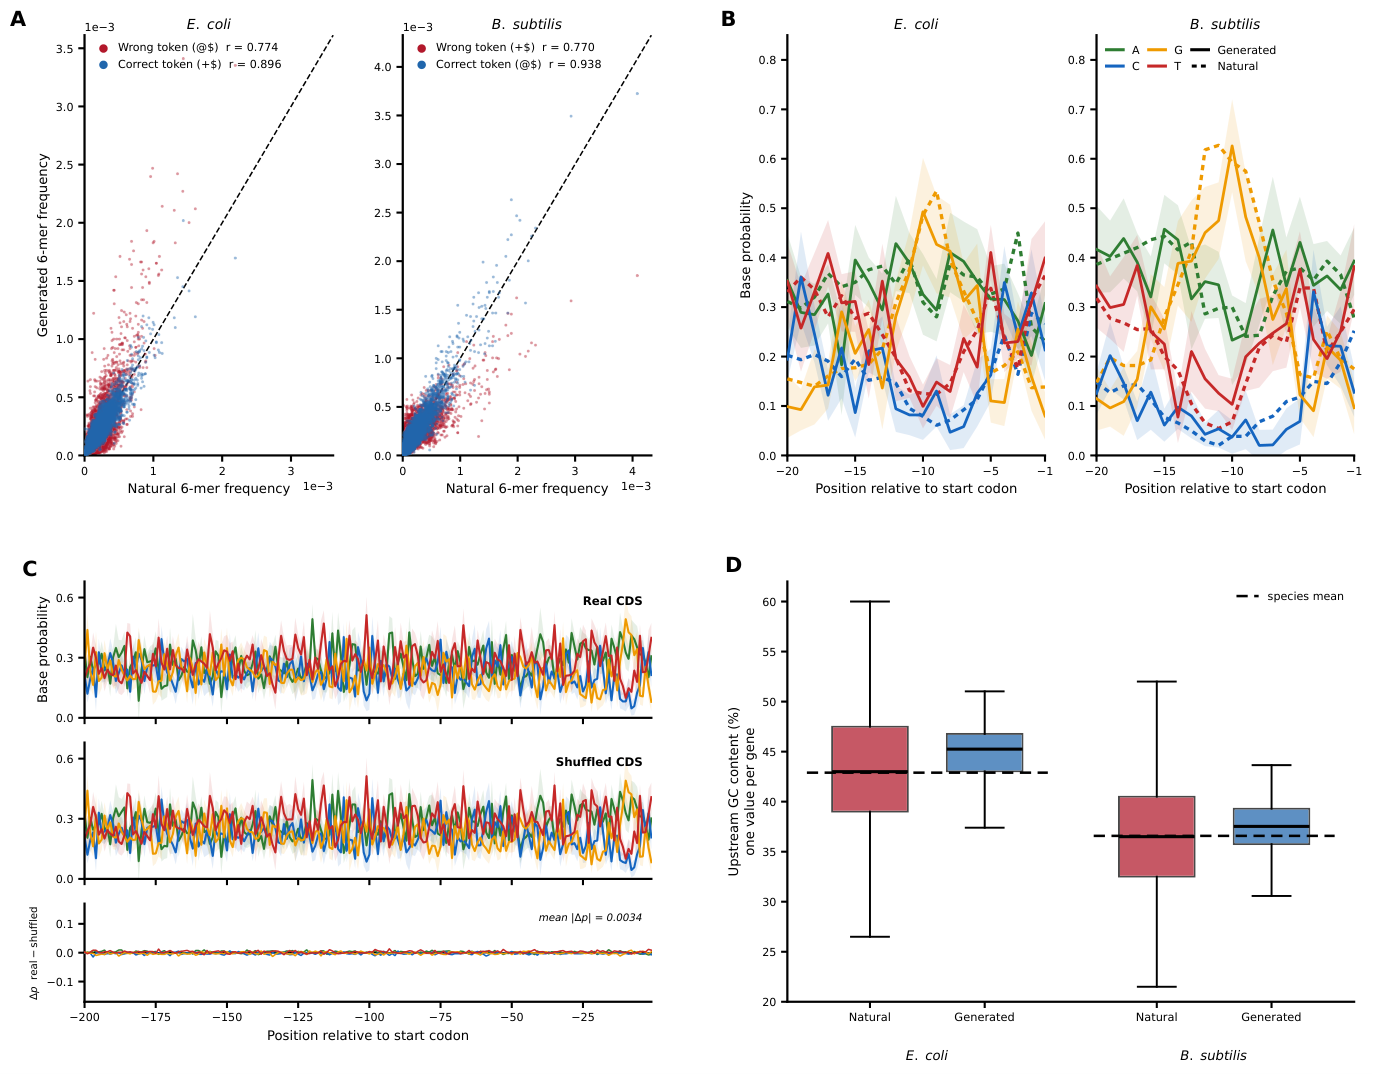

In [4]:
run("code/figure_3_cds_conditioning/render_fig_testset.py")
show("figures/cds_prompted_main.pdf")

## Fig. A.1 — where the CDS sensitivity sits

`figures/supp_kl_perposition.pdf` <- `code/figure_3_cds_conditioning/make_kl_perposition_figure.py`

Per-position KL between the predictions under the real CDS and under each
perturbation, for both species. Also writes
`results/supp_kl_perposition_stats.csv` with the totals, peaks and the
enrichment at the Shine--Dalgarno region.

OK   code/figure_3_cds_conditioning/make_kl_perposition_figure.py
    bsubtilis        C1 synonymous codons permuted       0.581              0.003            200      0.008         9.756          1.774          30.973            1.239
    bsubtilis        C2       codon order shuffled       1.142              0.006            200      0.017         9.013          1.639          34.046            1.362
    bsubtilis        C3           a different gene       2.172              0.011            200      0.025         7.458          1.356          34.317            1.373
    bsubtilis        C4                CDS removed       2.806              0.014             31      0.028         6.381          1.160          37.092            1.484
    bsubtilis        C5       codons 1–30 shuffled       0.034              0.000            193      0.000        11.592          2.108          25.194            1.008
    bsubtilis        C6     codons 31–end shuffled       1.035              0.005   

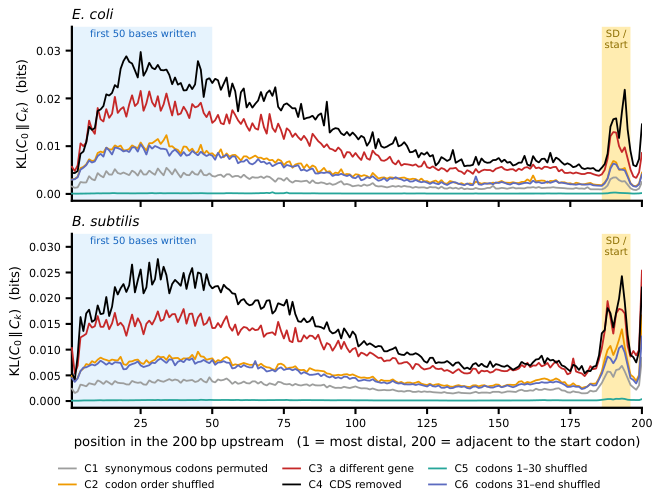

In [5]:
run("code/figure_3_cds_conditioning/make_kl_perposition_figure.py")
show("figures/supp_kl_perposition.pdf")

## Fig. 4

`figures/fig_retrieval.pdf` <- `code/figure_4_retrieval/make_fig.py`


OK   code/figure_4_retrieval/make_fig.py
    written: figures/fig_retrieval.pdf
    written: figures/fig_retrieval.png


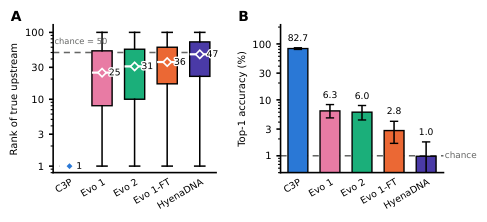

In [6]:
run("code/figure_4_retrieval/make_fig.py", ['--results', 'data/retrieval/results', '--pdf', 'figures/fig_retrieval.pdf', '--png', 'figures/fig_retrieval.png'])
show("figures/fig_retrieval.pdf")

## Fig. C.1

`figures/supp_cds_completion_probabilities.pdf` <- `code/figure_C1_cds_completion/plot_profiles.py`


OK   code/figure_C1_cds_completion/plot_profiles.py
    wrote figures/supp_cds_completion_probabilities.pdf


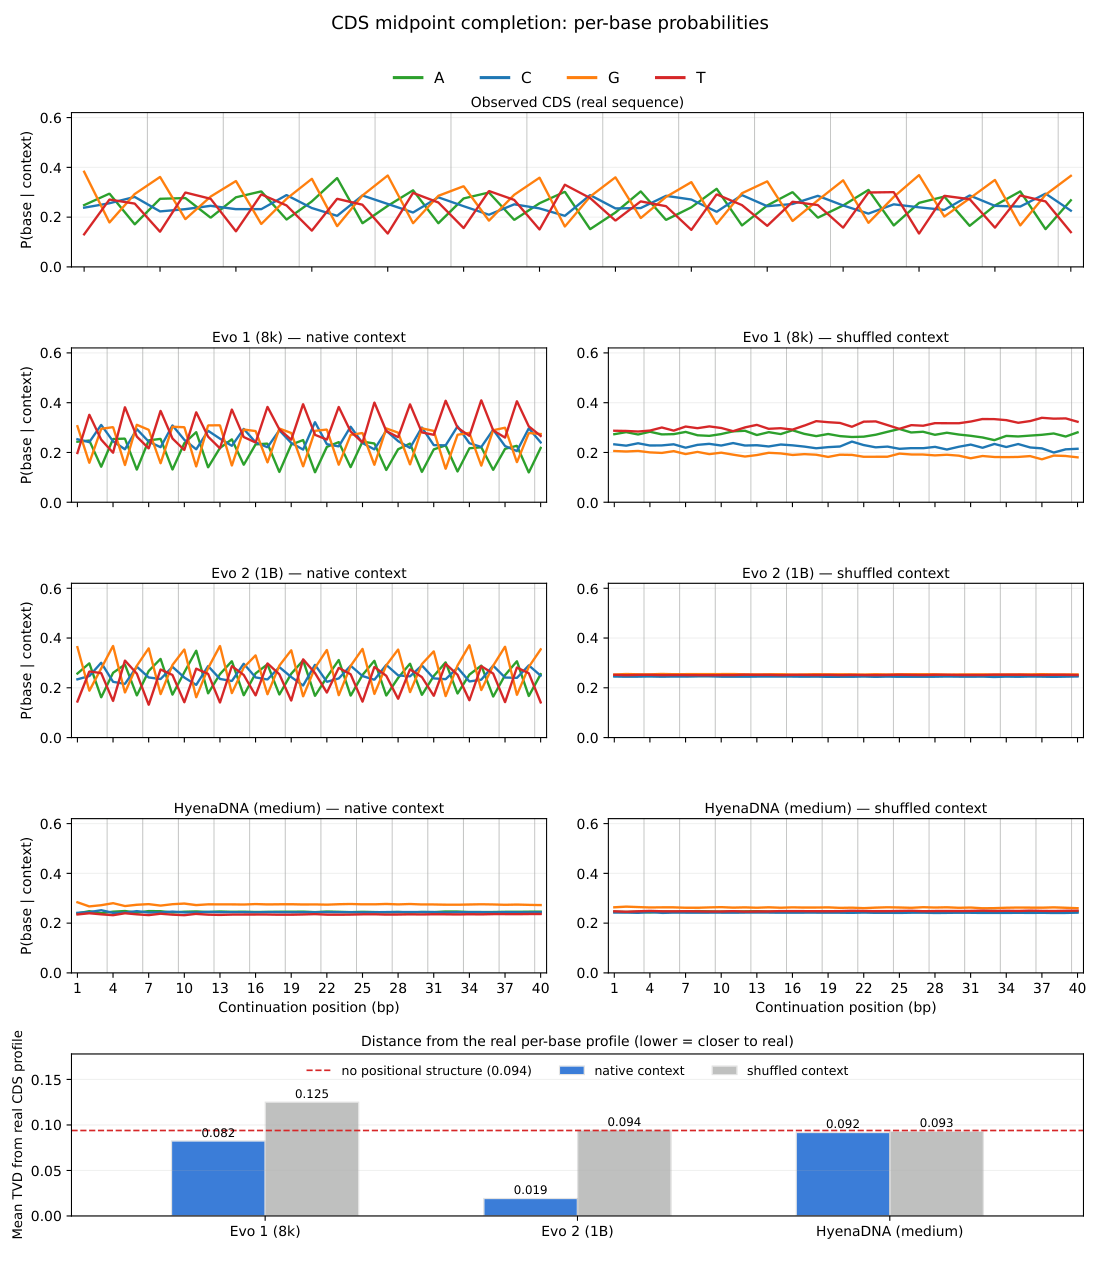

In [7]:
run("code/figure_C1_cds_completion/plot_profiles.py", ['--profiles', 'results/cds_completion_profiles.npz', '--out', 'figures/supp_cds_completion_probabilities.pdf'])
show("figures/supp_cds_completion_probabilities.pdf")

## Fig. C.2

`figures/fig_cds_vs_upstream_gap.pdf` <- `code/figure_C2_cds_vs_upstream_gap/make_cds_vs_upstream_gap.py`


OK   code/figure_C2_cds_vs_upstream_gap/make_cds_vs_upstream_gap.py
    track    model  mean_tvd  flat_reference  sampling_floor  tvd_over_flat  n_positions  n_genes
         CDS     evo1    0.0825          0.0939          0.0263         0.8782           40      672
         CDS     evo2    0.0192          0.0939          0.0263         0.2050           40      672
         CDS hyenadna    0.0918          0.0939          0.0263         0.9772           40      672
    upstream     evo1    0.0776          0.0670          0.0307         1.1590           41      487
    upstream     evo2    0.0701          0.0670          0.0307         1.0461           41      487
    upstream hyenadna    0.0669          0.0670          0.0307         0.9985           41      487
    wrote /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/figures/fig_cds_vs_upstream_gap.pdf


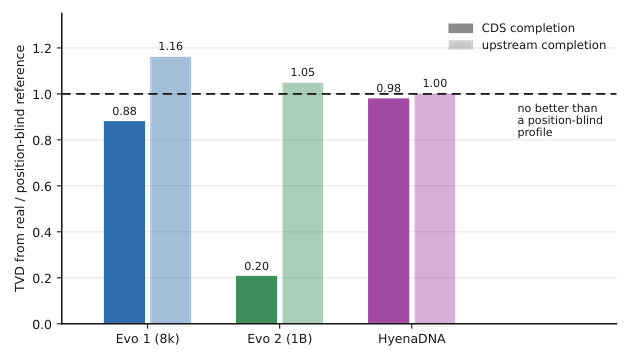

In [8]:
run("code/figure_C2_cds_vs_upstream_gap/make_cds_vs_upstream_gap.py")
show("figures/fig_cds_vs_upstream_gap.pdf")

## Fig. E.1

`figures/upstream_only_dataset_supp.pdf` <- `code/figure_E1_benchmark_composition/make_upstream_only_dataset_figure.py`


OK   code/figure_E1_benchmark_composition/make_upstream_only_dataset_figure.py
    wrote /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/results/upstream_only_dataset_supp.pdf
    wrote /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/results/upstream_only_dataset_supp.png
    wrote /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/figures/upstream_only_dataset_supp.pdf
    wrote /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/figures/upstream_only_dataset_supp.png


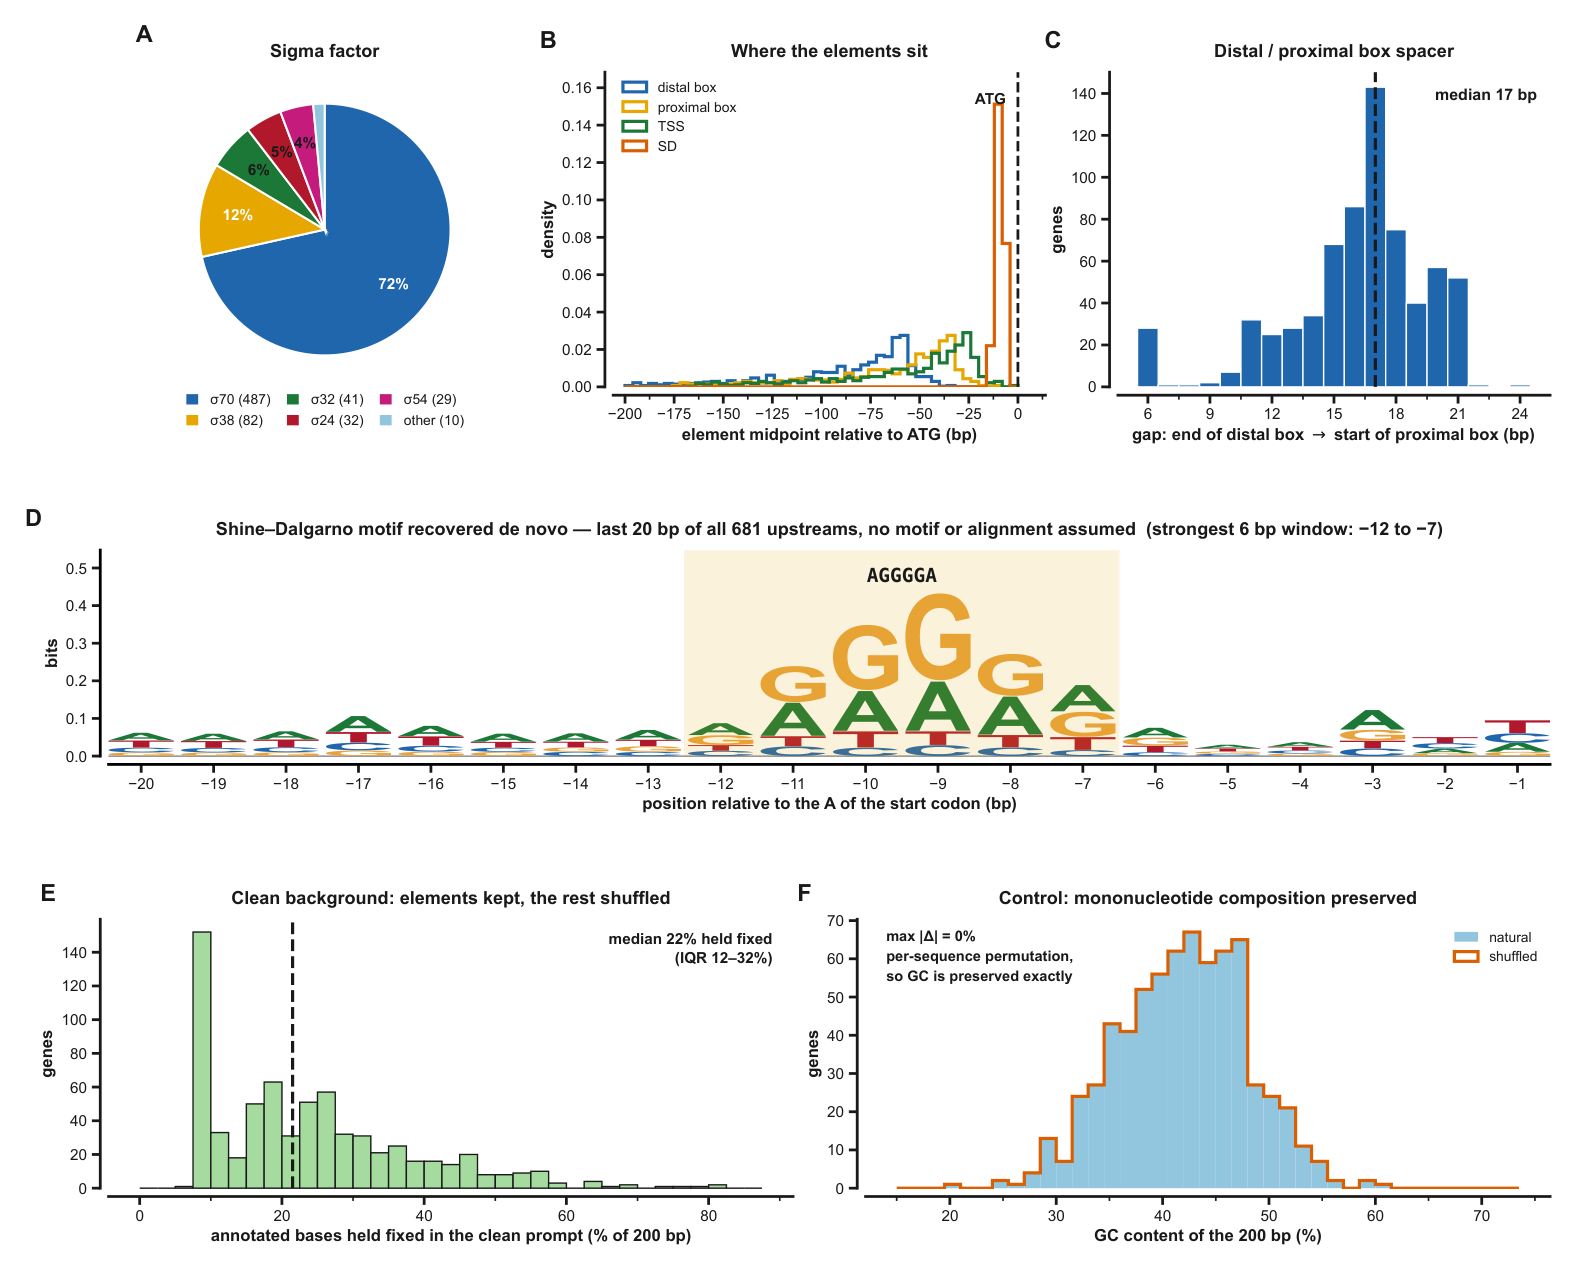

In [9]:
run("code/figure_E1_benchmark_composition/make_upstream_only_dataset_figure.py")
show("figures/upstream_only_dataset_supp.pdf")

## Fig. E.2

`figures/upstream_only_logos.pdf` <- `code/figure_E2_promoter_logos/upstream_only_figure.py`


OK   code/figure_E2_promoter_logos/upstream_only_figure.py
    max |GC_leaked - GC_clean| = 21.2
    4-mer pairwise distance: leaked 0.5891 | clean 0.6095
    logo groups: [('sigma70', 487), ('sigma38', 82), ('sigma32', 41), ('sigma24', 32), ('sigma54', 29)]
    wrote:
      /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/results/upstream_only_dataset.pdf  (179 kB)
      /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/results/upstream_only_dataset_p1.png  (598 kB)
      /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/results/upstream_only_logos.pdf  (153 kB)
      /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/results/upstream_only_logos.png  (689 kB)


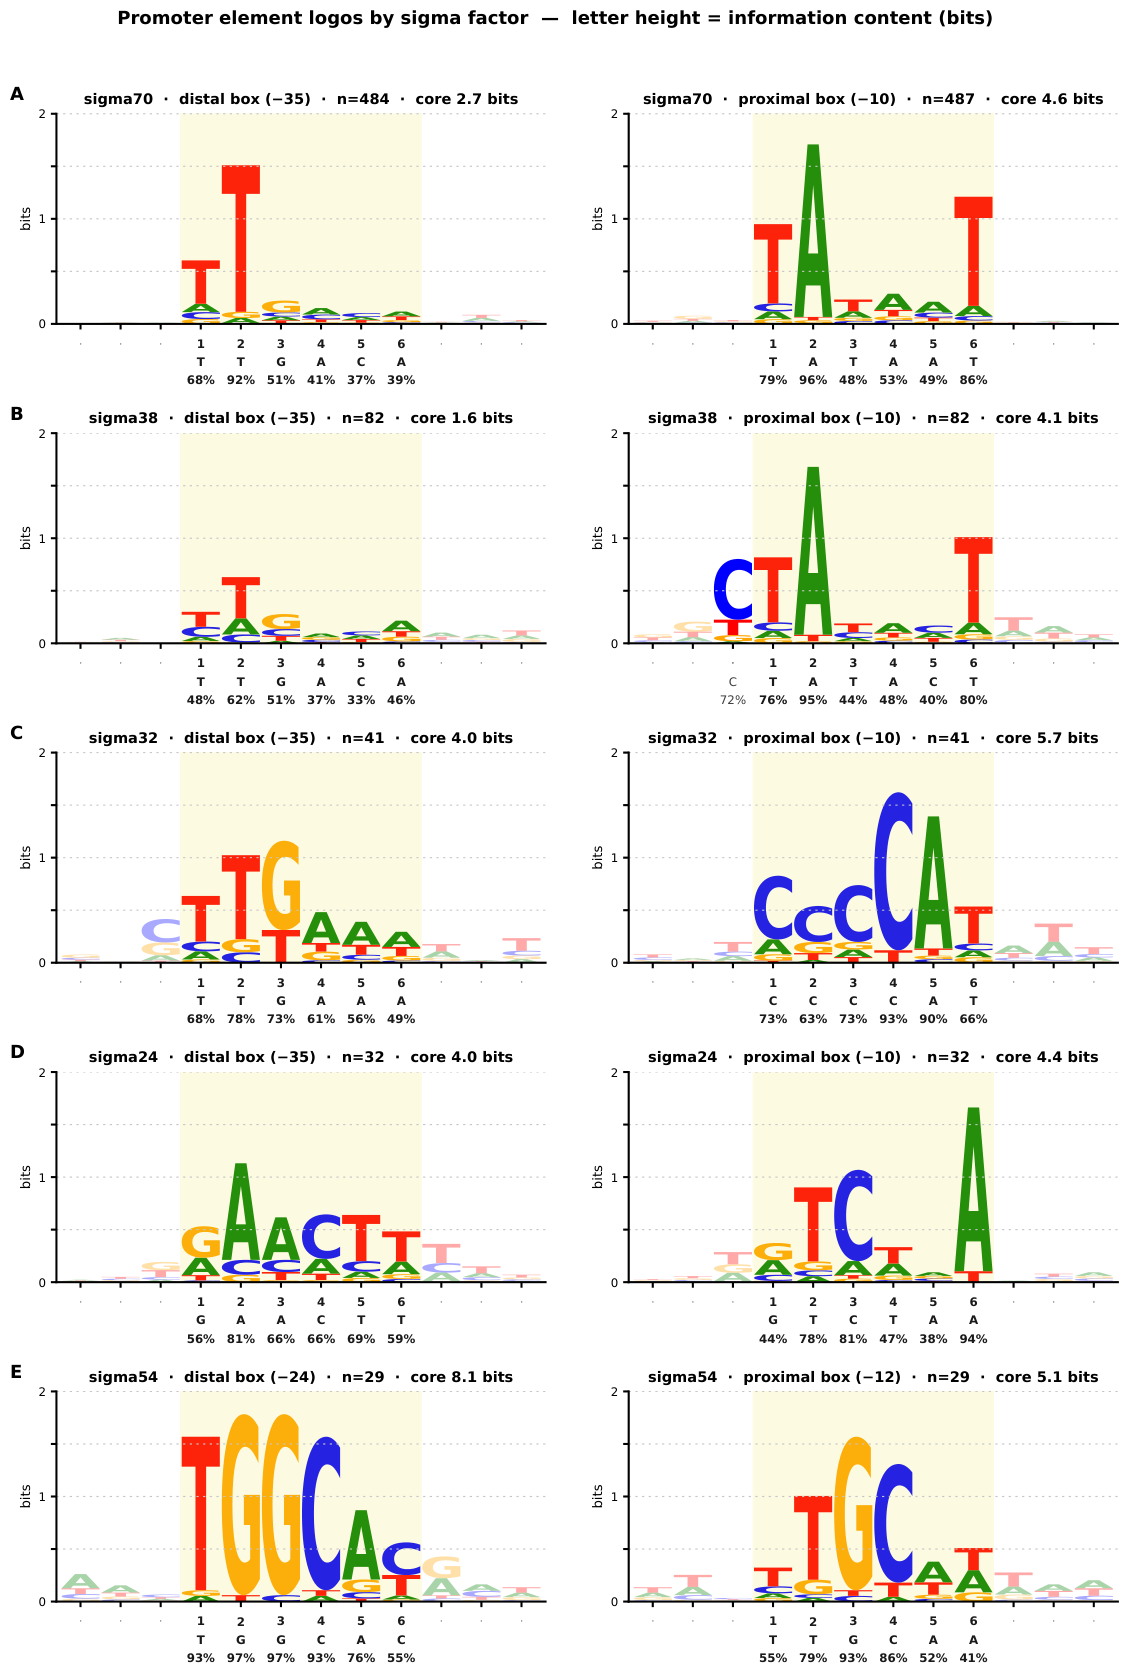

In [10]:
run("code/figure_E2_promoter_logos/upstream_only_figure.py")
show("figures/upstream_only_logos.pdf")

## Fig. E.3

`figures/supp_spacer_histograms.pdf` <- `code/figure_E3_spacer_histograms/make_supp_spacer_histograms.py`


OK   code/figure_E3_spacer_histograms/make_supp_spacer_histograms.py
    wrote /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/results/supp_spacer_histograms.pdf
    wrote /Users/marcamil/PhD/ICBINB_BIO_NeurIPS2026/figures/supp_spacer_histograms.pdf


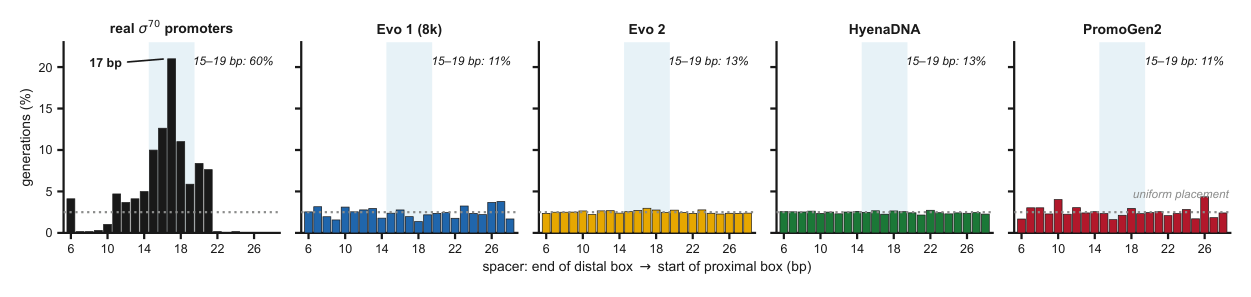

In [11]:
run("code/figure_E3_spacer_histograms/make_supp_spacer_histograms.py")
show("figures/supp_spacer_histograms.pdf")

## Fig. F.1

`figures/supp_training_composition.pdf` <- `code/figure_F1_training_corpus/noncoding_analyse_and_plot.py`


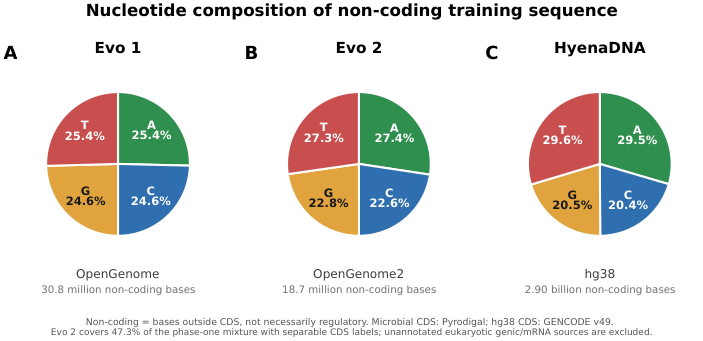

In [12]:
# Fig. F.1 needs the non-coding corpus scan, which is not shipped
# (tens of GB of training corpora). The cached aggregate it plots is in the repo:
#     results/training_corpus_composition/noncoding_nucleotide_composition.json
# Redraw from that cache by pointing the script at it with --previous-json.
show("figures/supp_training_composition.pdf")

## Figures not in the current draft

These still ship in `figures/` but are no longer cited by `main.tex`:
`supp_fig1a_dataset.pdf`, `fig_loss_decomposition.pdf`, `supp_promoter_geometry.pdf`,
`supp_element_composition.pdf`. Their scripts are kept so the panels can be revived.


In [13]:
for s, pdf in [
    ("code/not_in_current_draft/make_supp_fig1a_dataset.py",      "figures/supp_fig1a_dataset.pdf"),
    ("code/not_in_current_draft/make_loss_decomposition_figure.py",     "figures/fig_loss_decomposition.pdf"),
    ("code/not_in_current_draft/make_supp_promoter_geometry.py",   "figures/supp_promoter_geometry.pdf"),
    ("code/not_in_current_draft/make_supp_element_composition.py", "figures/supp_element_composition.pdf"),
]:
    print(s, "->", pdf)

code/not_in_current_draft/make_supp_fig1a_dataset.py -> figures/supp_fig1a_dataset.pdf
code/not_in_current_draft/make_loss_decomposition_figure.py -> figures/fig_loss_decomposition.pdf
code/not_in_current_draft/make_supp_promoter_geometry.py -> figures/supp_promoter_geometry.pdf
code/not_in_current_draft/make_supp_element_composition.py -> figures/supp_element_composition.pdf
